<a href="https://colab.research.google.com/github/abhijeetsomashila1/Indoor-AQ-BIQ/blob/main/Calibration_BuildIQ.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Air Quality Sensor Calibration Notebook
This notebook calibrates 7 low-cost sensor nodes against Aeroqual reference monitors for PM2.5, PM10, and CO2 following standard sensor evaluation protocols.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error

print("Step 1: Libraries imported successfully.")

Step 1: Libraries imported successfully.


In [ ]:
nodes = {}
node_files = {
    1: '/content/1.csv',
    2: '/content/2.csv',
    3: '/content/3.csv',
    4: '/content/4.csv',
    5: '/content/5.csv',
    6: '/content/6.csv',
    7: '/content/7.csv'
}

for node_id, filepath in sorted(node_files.items()):
    df = pd.read_csv(filepath)
    df.columns = df.columns.str.strip().str.lower()

    rename_dict = {
        'pm25': 'PM2.5_raw',
        'pm2.5': 'PM2.5_raw',
        'pm10': 'PM10_raw',
        'co2': 'CO2_raw',
        'temp': 'Temperature',
        'humidity': 'Humidity'
    }
    df = df.rename(columns=rename_dict)

    keep_cols = ['created_at', 'PM2.5_raw', 'PM10_raw', 'CO2_raw', 'Temperature', 'Humidity']
    df = df[[c for c in keep_cols if c in df.columns]]

    for col in ['PM2.5_raw', 'PM10_raw', 'CO2_raw', 'Temperature', 'Humidity']:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce')
            df.loc[df[col] < 0, col] = np.nan

    df['created_at'] = pd.to_datetime(df['created_at'], errors='coerce')
    df = df.dropna(subset=['created_at'])

    if df['created_at'].dt.tz is None:
        df['created_at'] = df['created_at'].dt.tz_localize('UTC').dt.tz_convert('Asia/Kolkata')
    else:
        df['created_at'] = df['created_at'].dt.tz_convert('Asia/Kolkata')

    df['created_at'] = df['created_at'].dt.tz_localize(None)
    nodes[node_id] = df.sort_values('created_at').reset_index(drop=True)
    print(f"Node {node_id}: {len(df)} rows | {df['created_at'].min()} to {df['created_at'].max()}")

Node 1: 26562 rows | 2026-10-06 19:19:25 to 2026-10-12 13:25:57
Node 2: 25793 rows | 2026-10-06 19:20:05 to 2026-10-12 13:25:57
Node 3: 26564 rows | 2026-10-06 19:20:13 to 2026-10-12 13:26:05
Node 4: 26416 rows | 2026-10-06 19:20:08 to 2026-10-12 13:26:00
Node 5: 25528 rows | 2026-10-06 19:20:00 to 2026-10-12 13:26:03
Node 6: 26594 rows | 2026-10-06 19:20:39 to 2026-10-12 13:25:59
Node 7: 26145 rows | 2026-10-06 19:20:21 to 2026-10-12 13:25:58


In [ ]:
pm_temp = pd.read_csv('/content/PM_aero.csv')
co2_temp = pd.read_csv('/content/co2_aero.csv')
print("=== PM Aero Columns ===", pm_temp.columns.tolist())
print("=== CO2 Aero Columns ===", co2_temp.columns.tolist())

pm_aero = pm_temp.copy()
pm_aero.columns = pm_aero.columns.str.strip()
co2_aero = co2_temp.copy()
co2_aero.columns = co2_aero.columns.str.strip()

date_col_pm = [c for c in pm_aero.columns if 'date' in c.lower() or 'time' in c.lower()][0]
date_col_co2 = [c for c in co2_aero.columns if 'date' in c.lower() or 'time' in c.lower()][0]

pm_aero = pm_aero.rename(columns={date_col_pm: 'created_at'})
co2_aero = co2_aero.rename(columns={date_col_co2: 'created_at'})

pm_aero['created_at'] = pd.to_datetime(pm_aero['created_at'], dayfirst=True, errors='coerce')
co2_aero['created_at'] = pd.to_datetime(co2_aero['created_at'], dayfirst=True, errors='coerce')

pm_aero = pm_aero.dropna(subset=['created_at']).sort_values('created_at').reset_index(drop=True)
co2_aero = co2_aero.dropna(subset=['created_at']).sort_values('created_at').reset_index(drop=True)

pm25_col = [c for c in pm_aero.columns if 'pm2.5' in c.lower() or 'pm25' in c.lower() or 'pm 2.5' in c.lower()][0]
pm10_col = [c for c in pm_aero.columns if 'pm10' in c.lower() or 'pm 10' in c.lower()][0]
co2_val_col = [c for c in co2_aero.columns if 'co2' in c.lower() or 'co 2' in c.lower()][0]

pm_aero[pm25_col] = pd.to_numeric(pm_aero[pm25_col], errors='coerce')
pm_aero[pm10_col] = pd.to_numeric(pm_aero[pm10_col], errors='coerce')
co2_aero[co2_val_col] = pd.to_numeric(co2_aero[co2_val_col], errors='coerce')

if pm_aero[pm25_col].max() < 2.0:
    print("Converting PM from mg/m3 to ug/m3.")
    pm_aero['PM2.5_ref'] = pm_aero[pm25_col] * 1000.0
    pm_aero['PM10_ref'] = pm_aero[pm10_col] * 1000.0
else:
    pm_aero['PM2.5_ref'] = pm_aero[pm25_col]
    pm_aero['PM10_ref'] = pm_aero[pm10_col]

co2_aero['CO2_ref'] = co2_aero[co2_val_col]
pm_ref_df = pm_aero[['created_at', 'PM2.5_ref', 'PM10_ref']].copy()
co2_ref_df = co2_aero[['created_at', 'CO2_ref']].copy()

print(f"PM Ref: {len(pm_ref_df)} rows, Range: {pm_ref_df['created_at'].min()} to {pm_ref_df['created_at'].max()}")
print(f"CO2 Ref: {len(co2_ref_df)} rows, Range: {co2_ref_df['created_at'].min()} to {co2_ref_df['created_at'].max()}")

=== PM Aero Columns === ['Date Time', ' PM10(ppm)', ' PM2.5(ppm)']
=== CO2 Aero Columns === ['Date Time', ' CO2(ppm)']
Converting PM from mg/m3 to ug/m3.
PM Ref: 3965 rows, Range: 2026-10-06 18:07:00 to 2026-10-09 23:55:00
CO2 Ref: 2584 rows, Range: 2026-10-10 15:13:00 to 2026-10-12 13:26:00


In [ ]:
pm_start, pm_end = pd.to_datetime('2026-10-06 19:20:00'), pd.to_datetime('2026-10-09 12:00:00')
co2_w1_start, co2_w1_end = pd.to_datetime('2026-10-10 15:00:00'), pd.to_datetime('2026-10-10 21:00:00')
co2_w2_start, co2_w2_end = pd.to_datetime('2026-10-11 01:23:00'), pd.to_datetime('2026-10-12 13:20:00')

pm_ref_filtered = pm_ref_df[(pm_ref_df['created_at'] >= pm_start) & (pm_ref_df['created_at'] <= pm_end)].copy()
co2_ref_filtered = co2_ref_df[
    ((co2_ref_df['created_at'] >= co2_w1_start) & (co2_ref_df['created_at'] <= co2_w1_end)) |
    ((co2_ref_df['created_at'] >= co2_w2_start) & (co2_ref_df['created_at'] <= co2_w2_end))
].copy()

nodes_filtered = {}
for n_id, df_node in nodes.items():
    df_pm = df_node[(df_node['created_at'] >= pm_start) & (df_node['created_at'] <= pm_end)].copy()
    df_co2 = df_node[
        ((df_node['created_at'] >= co2_w1_start) & (df_node['created_at'] <= co2_w1_end)) |
        ((df_node['created_at'] >= co2_w2_start) & (df_node['created_at'] <= co2_w2_end))
    ].copy()
    nodes_filtered[n_id] = {'pm': df_pm, 'co2': df_co2}
    print(f"Node {n_id}: PM ({len(df_pm)}), CO2 ({len(df_co2)}) in windows.")

Node 1: PM (15457), CO2 (9989) in windows.
Node 2: PM (14986), CO2 (9737) in windows.
Node 3: PM (15463), CO2 (9987) in windows.
Node 4: PM (15355), CO2 (9952) in windows.
Node 5: PM (14468), CO2 (9974) in windows.
Node 6: PM (15399), CO2 (9985) in windows.
Node 7: PM (15138), CO2 (9901) in windows.


In [ ]:
iqr_records = []
nodes_cleaned = {}

for n_id, data_dict in nodes_filtered.items():
    df_pm = data_dict['pm'].copy()
    df_co2 = data_dict['co2'].copy()

    for col_name, max_limit, label in [('PM2.5_raw', 999, 'pm'), ('PM10_raw', 999, 'pm'), ('CO2_raw', 10000, 'co2')]:
        target_df = df_pm if label == 'pm' else df_co2
        valid_s = target_df[col_name].dropna()
        valid_s = valid_s[valid_s <= max_limit]

        if len(valid_s) > 0:
            q25, q75 = valid_s.quantile(0.25), valid_s.quantile(0.75)
            iqr = q75 - q25
            lower, upper = q25 - 1.5 * iqr, q75 + 1.5 * iqr
            cleaned_s = valid_s[(valid_s >= lower) & (valid_s <= upper)]
            removed = len(target_df) - len(cleaned_s)
            target_df.loc[~target_df.index.isin(cleaned_s.index), col_name] = np.nan
            iqr_records.append([f"Node {n_id}", col_name, round(lower, 2), round(upper, 2), removed, len(cleaned_s)])

    nodes_cleaned[n_id] = {'pm': df_pm, 'co2': df_co2}

iqr_df = pd.DataFrame(iqr_records, columns=['Node', 'Parameter', 'Lower Bound', 'Upper Bound', 'Outliers Removed', 'Points Kept'])
display(iqr_df)

,Node,Parameter,Lower Bound,Upper Bound,Outliers Removed,Points Kept
0,Node 1,PM2.5_raw,-175.95,394.05,437,15020
1,Node 1,PM10_raw,-188.75,441.25,408,15049
2,Node 1,CO2_raw,383.50,491.50,1592,8397
3,Node 2,PM2.5_raw,-172.00,393.60,638,14348
4,Node 2,PM10_raw,-187.75,438.25,599,14387
5,Node 2,CO2_raw,356.00,548.00,1359,8378
6,Node 3,PM2.5_raw,-160.25,368.15,658,14805
7,Node 3,PM10_raw,-173.47,417.12,576,14887
8,Node 3,CO2_raw,299.00,707.00,935,9052
9,Node 4,PM2.5_raw,-162.61,350.49,849,14506


In [ ]:
nodes_resampled = {}

pm_ref_res = pm_ref_filtered.set_index('created_at').resample('1min', label='right', closed='right').mean(numeric_only=True).round(3).reset_index()
co2_ref_res = co2_ref_filtered.set_index('created_at').resample('1min', label='right', closed='right').mean(numeric_only=True).round(3).reset_index()

for n_id, data_dict in nodes_cleaned.items():
    df_pm_res = data_dict['pm'].set_index('created_at').resample('1min', label='right', closed='right').mean(numeric_only=True).round(3).reset_index()
    df_co2_res = data_dict['co2'].set_index('created_at').resample('1min', label='right', closed='right').mean(numeric_only=True).round(3).reset_index()
    nodes_resampled[n_id] = {'pm': df_pm_res, 'co2': df_co2_res}

print("1-minute time equalization aggregation completed.")

1-minute time equalization aggregation completed.


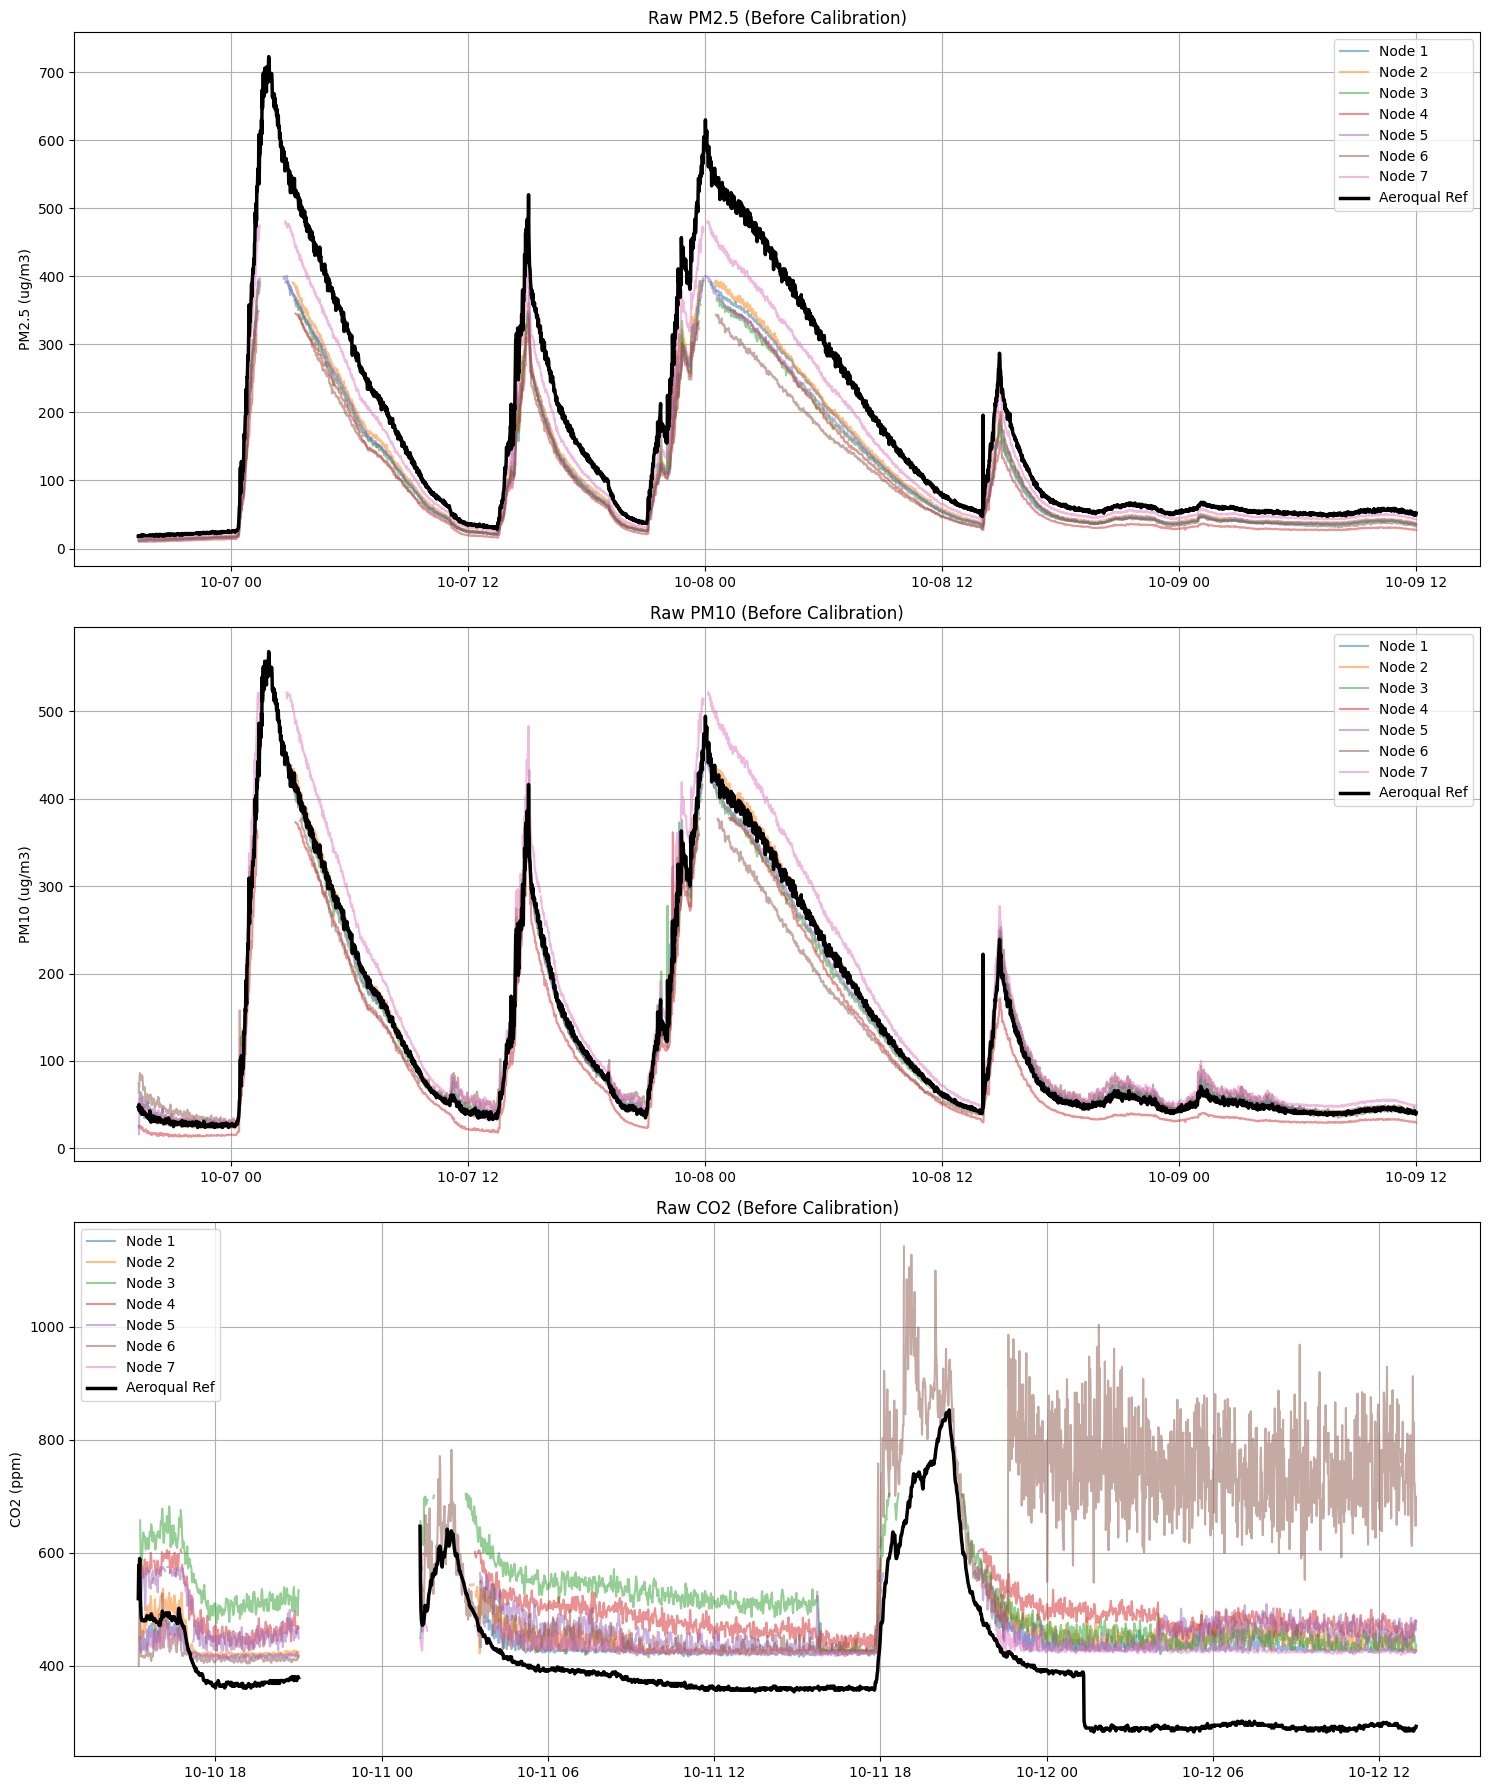

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(15, 18))

# PM2.5
for n_id, data in nodes_resampled.items():
    axes[0].plot(data['pm']['created_at'], data['pm']['PM2.5_raw'], label=f'Node {n_id}', alpha=0.5)
axes[0].plot(pm_ref_res['created_at'], pm_ref_res['PM2.5_ref'], color='black', linewidth=2.5, label='Aeroqual Ref')
axes[0].set_title('Raw PM2.5 (Before Calibration)')
axes[0].set_ylabel('PM2.5 (ug/m3)')
axes[0].legend()
axes[0].grid(True)

# PM10
for n_id, data in nodes_resampled.items():
    axes[1].plot(data['pm']['created_at'], data['pm']['PM10_raw'], label=f'Node {n_id}', alpha=0.5)
axes[1].plot(pm_ref_res['created_at'], pm_ref_res['PM10_ref'], color='black', linewidth=2.5, label='Aeroqual Ref')
axes[1].set_title('Raw PM10 (Before Calibration)')
axes[1].set_ylabel('PM10 (ug/m3)')
axes[1].legend()
axes[1].grid(True)

# CO2
for n_id, data in nodes_resampled.items():
    axes[2].plot(data['co2']['created_at'], data['co2']['CO2_raw'], label=f'Node {n_id}', alpha=0.5)
axes[2].plot(co2_ref_res['created_at'], co2_ref_res['CO2_ref'], color='black', linewidth=2.5, label='Aeroqual Ref')
axes[2].set_title('Raw CO2 (Before Calibration)')
axes[2].set_ylabel('CO2 (ppm)')
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()

In [ ]:
raw_comparison_records = []
merged_datasets = {}

for n_id, data in nodes_resampled.items():
    df_pm_m = pd.merge(data['pm'], pm_ref_res, on='created_at', how='inner').dropna(subset=['PM2.5_raw', 'PM10_raw', 'PM2.5_ref', 'PM10_ref'])
    df_co2_m = pd.merge(data['co2'], co2_ref_res, on='created_at', how='inner').dropna(subset=['CO2_raw', 'CO2_ref'])
    merged_datasets[n_id] = {'pm': df_pm_m, 'co2': df_co2_m}

    for param, node_col, ref_col, df_m in [('PM2.5', 'PM2.5_raw', 'PM2.5_ref', df_pm_m),
                                          ('PM10', 'PM10_raw', 'PM10_ref', df_pm_m),
                                          ('CO2', 'CO2_raw', 'CO2_ref', df_co2_m)]:
        if len(df_m) > 10:
            corr_vals = []
            lags = list(range(-15, 16))
            for lag in lags:
                shifted = df_m[node_col].shift(lag)
                valid_idx = shifted.notna() & df_m[ref_col].notna()
                if valid_idx.sum() > 10:
                    c, _ = pearsonr(shifted[valid_idx], df_m.loc[valid_idx, ref_col])
                    corr_vals.append(c)
                else:
                    corr_vals.append(0)
            best_lag = lags[np.argmax(np.abs(corr_vals))]
            best_corr = corr_vals[np.argmax(np.abs(corr_vals))]

            r_val, _ = pearsonr(df_m[node_col], df_m[ref_col])
            mae_val = mean_absolute_error(df_m[ref_col], df_m[node_col])
            rmse_val = np.sqrt(mean_squared_error(df_m[ref_col], df_m[node_col]))

            raw_comparison_records.append([n_id, param, len(df_m), round(r_val, 3), round(best_corr, 3), best_lag, round(mae_val, 2), round(rmse_val, 2)])

raw_comp_df = pd.DataFrame(raw_comparison_records, columns=['Node', 'Parameter', 'Merged Points', 'Raw Pearson', 'Best Lag Corr', 'Lag (min)', 'Raw MAE', 'Raw RMSE'])
display(raw_comp_df)

,Node,Parameter,Merged Points,Raw Pearson,Best Lag Corr,Lag (min),Raw MAE,Raw RMSE
0,1,PM2.5,3780,0.999,0.999,0,49.83,67.29
1,1,PM10,3780,0.998,0.998,0,4.16,6.83
2,1,CO2,2119,0.352,0.352,0,80.06,92.36
3,2,PM2.5,3710,0.999,0.999,0,43.62,59.98
4,2,PM10,3710,0.999,0.999,0,3.88,6.58
5,2,CO2,2164,0.430,0.434,-1,90.76,103.44
6,3,PM2.5,3717,0.997,0.998,-1,50.76,69.63
7,3,PM10,3717,0.996,0.996,-1,7.93,12.01
8,3,CO2,2281,0.870,0.873,-1,138.68,142.59
9,4,PM2.5,3661,0.997,0.997,-2,56.52,72.92


In [ ]:
calibration_results = []
models = {}

for n_id, datasets in merged_datasets.items():
    models[n_id] = {}
    for param, node_col, ref_col, df_m in [('PM2.5', 'PM2.5_raw', 'PM2.5_ref', datasets['pm']),
                                          ('PM10', 'PM10_raw', 'PM10_ref', datasets['pm']),
                                          ('CO2', 'CO2_raw', 'CO2_ref', datasets['co2'])]:
        if len(df_m) < 30:
            print(f"Node {n_id} {param} skipped: not enough points ({len(df_m)})")
            continue

        X = df_m[[node_col]].values
        y = df_m[ref_col].values

        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
        reg = LinearRegression()
        reg.fit(X_train, y_train)

        m_slope = reg.coef_[0]
        c_int = reg.intercept_
        y_pred = reg.predict(X_test)

        r2 = reg.score(X_test, y_test)
        mae = mean_absolute_error(y_test, y_pred)
        rmse = np.sqrt(mean_squared_error(y_test, y_pred))
        spearman, _ = spearmanr(X_test.flatten(), y_test)
        raw_rmse = np.sqrt(mean_squared_error(y_test, X_test.flatten()))

        calibration_results.append({
            'Node': f"Node {n_id}",
            'Parameter': param,
            'm': round(m_slope, 4),
            'c': round(c_int, 4),
            'R2': round(r2, 4),
            'RMSE_after': round(rmse, 3),
            'MAE_after': round(mae, 3),
            'N_points': len(df_m),
            'Raw_RMSE': round(raw_rmse, 3)
        })
        models[n_id][param] = {'m': m_slope, 'c': c_int}

results_df = pd.DataFrame(calibration_results)
results_df.to_csv('/content/calibration_coefficients.csv', index=False)
display(results_df)

,Node,Parameter,m,c,R2,RMSE_after,MAE_after,N_points,Raw_RMSE
0,Node 1,PM2.5,1.4188,2.8236,0.9977,7.310,4.501,3780,67.290
1,Node 1,PM10,1.0154,-1.6994,0.9974,5.882,3.763,3780,6.176
2,Node 1,CO2,1.2774,-197.2479,0.1344,50.351,43.928,2119,92.083
3,Node 2,PM2.5,1.3893,-0.4694,0.9974,7.320,4.028,3710,59.249
4,Node 2,PM10,0.9858,-0.0563,0.9970,5.966,3.478,3710,6.539
5,Node 2,CO2,0.9069,-48.7610,0.1567,50.989,45.622,2164,102.466
6,Node 3,PM2.5,1.4832,0.1669,0.9939,10.867,5.731,3717,67.785
7,Node 3,PM10,1.0576,-4.5003,0.9914,9.841,5.945,3717,11.502
8,Node 3,CO2,0.8980,-87.3131,0.7649,32.667,25.004,2281,141.274
9,Node 4,PM2.5,1.4818,11.2551,0.9941,10.461,6.117,3661,72.984


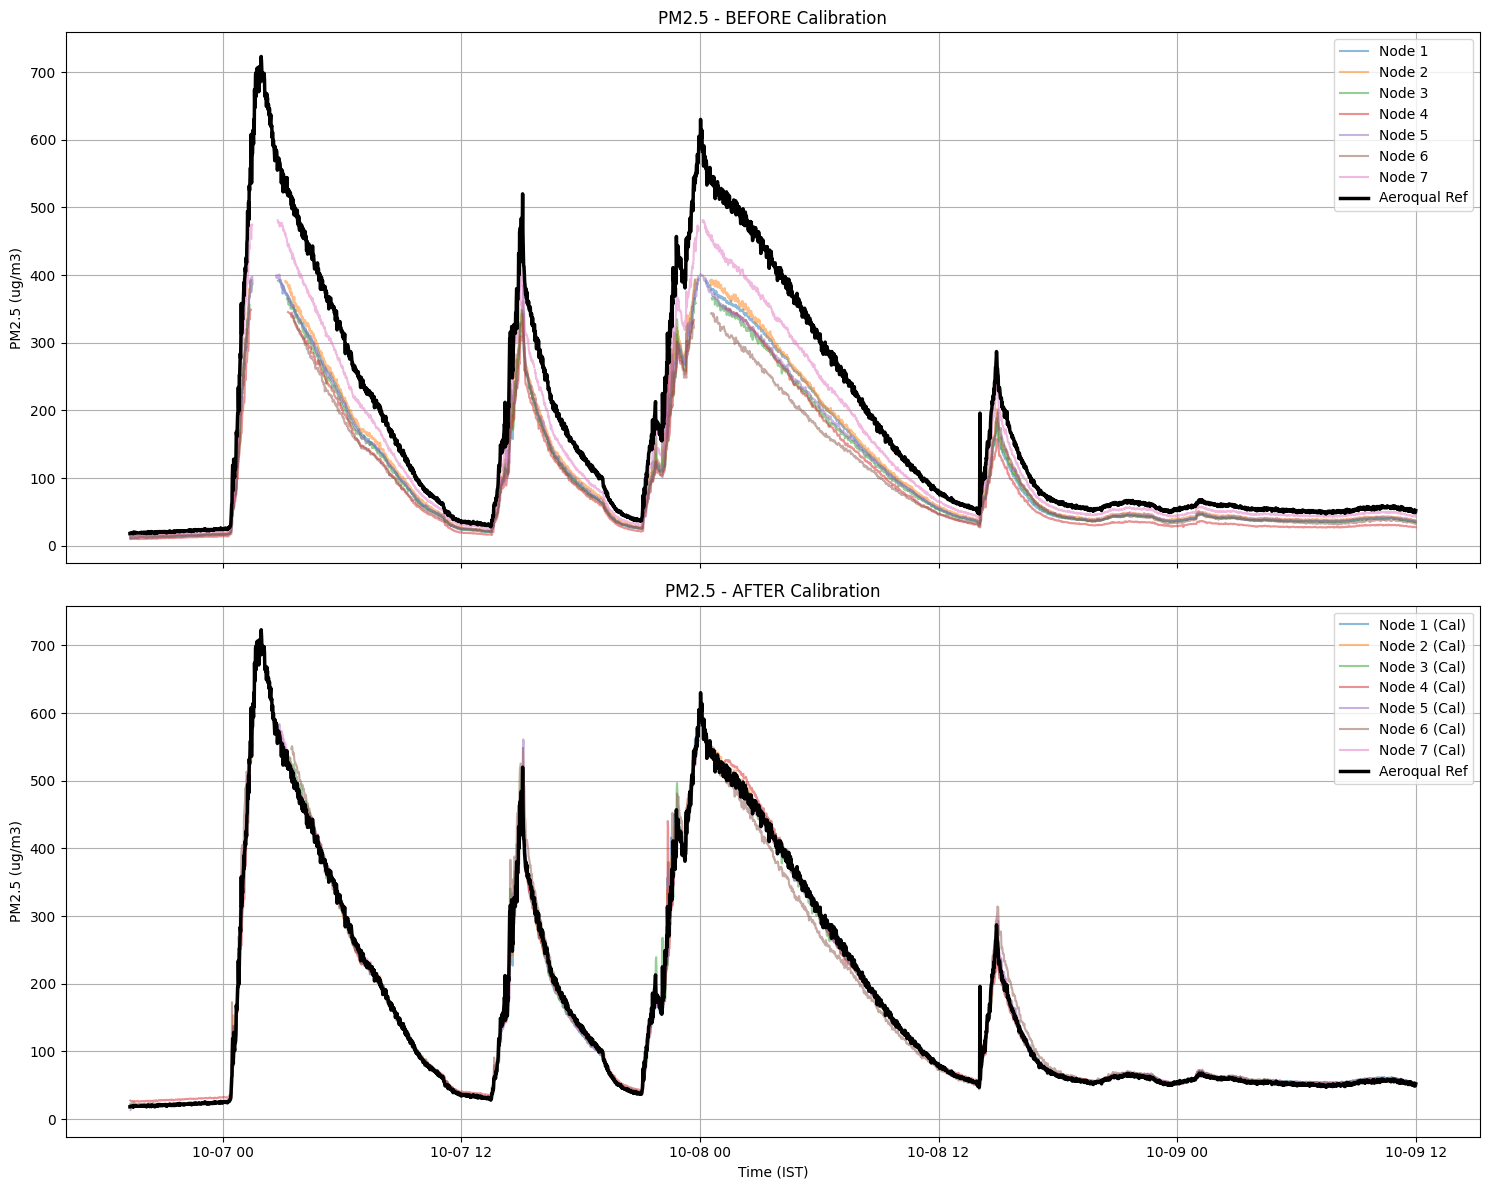

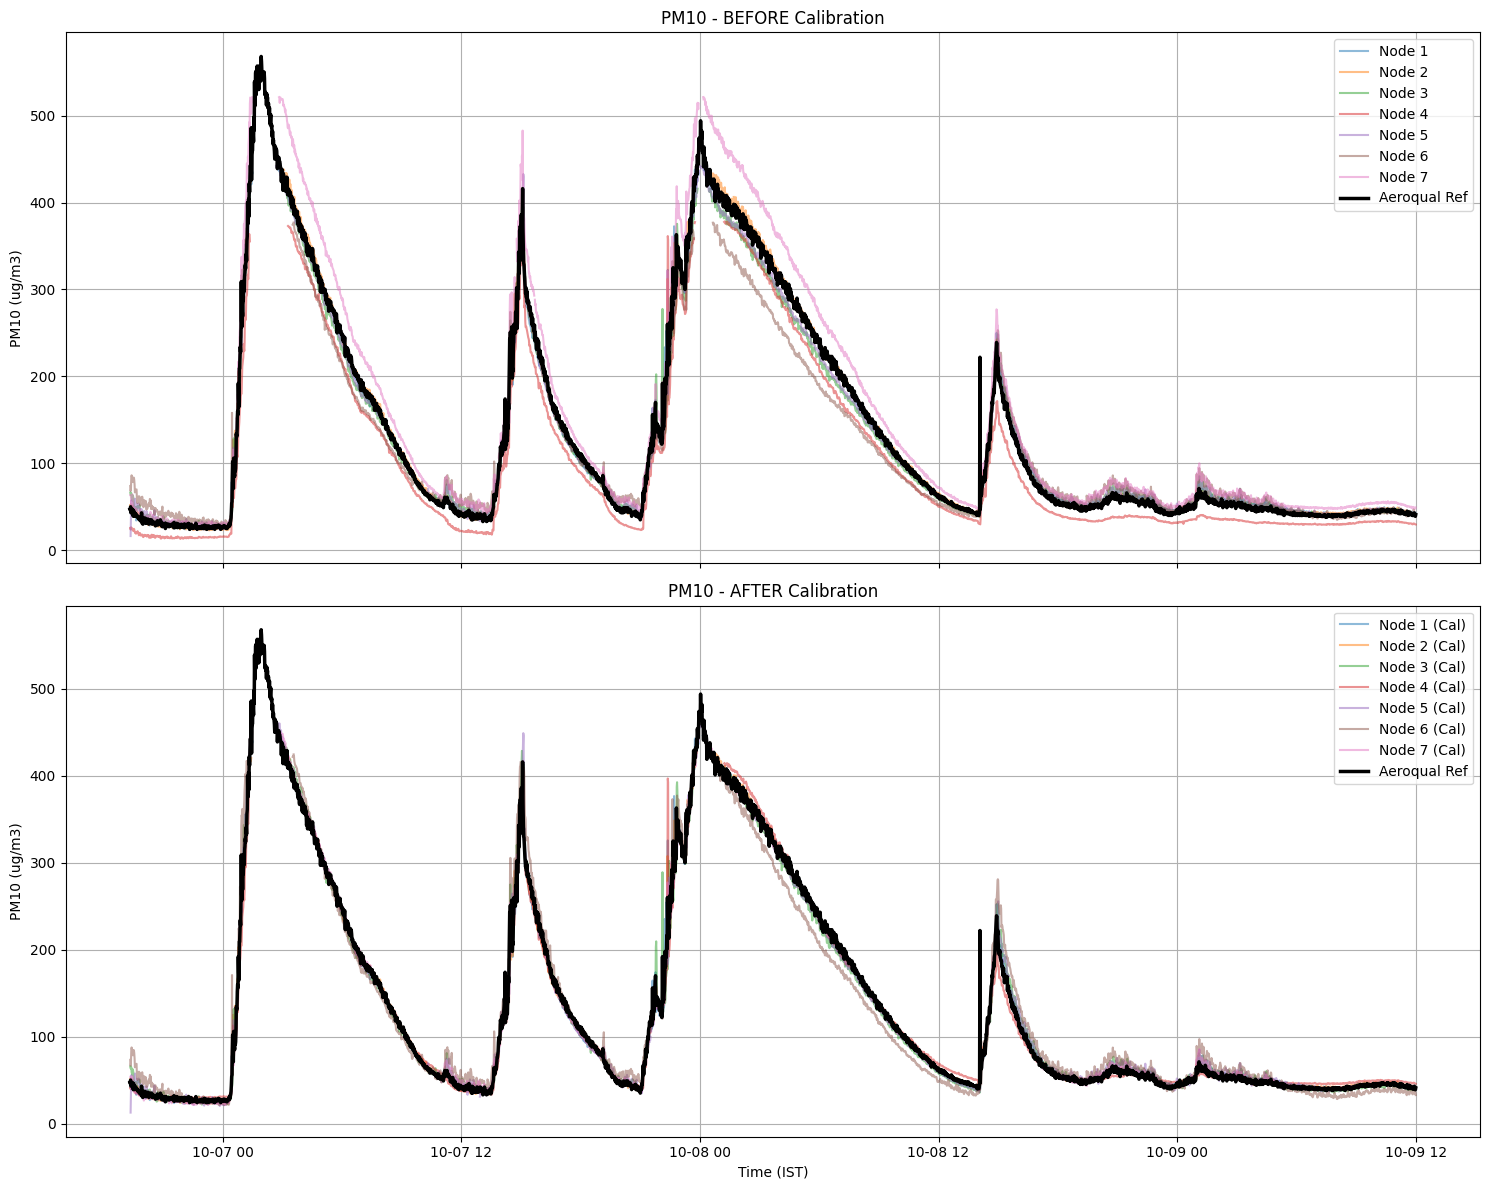

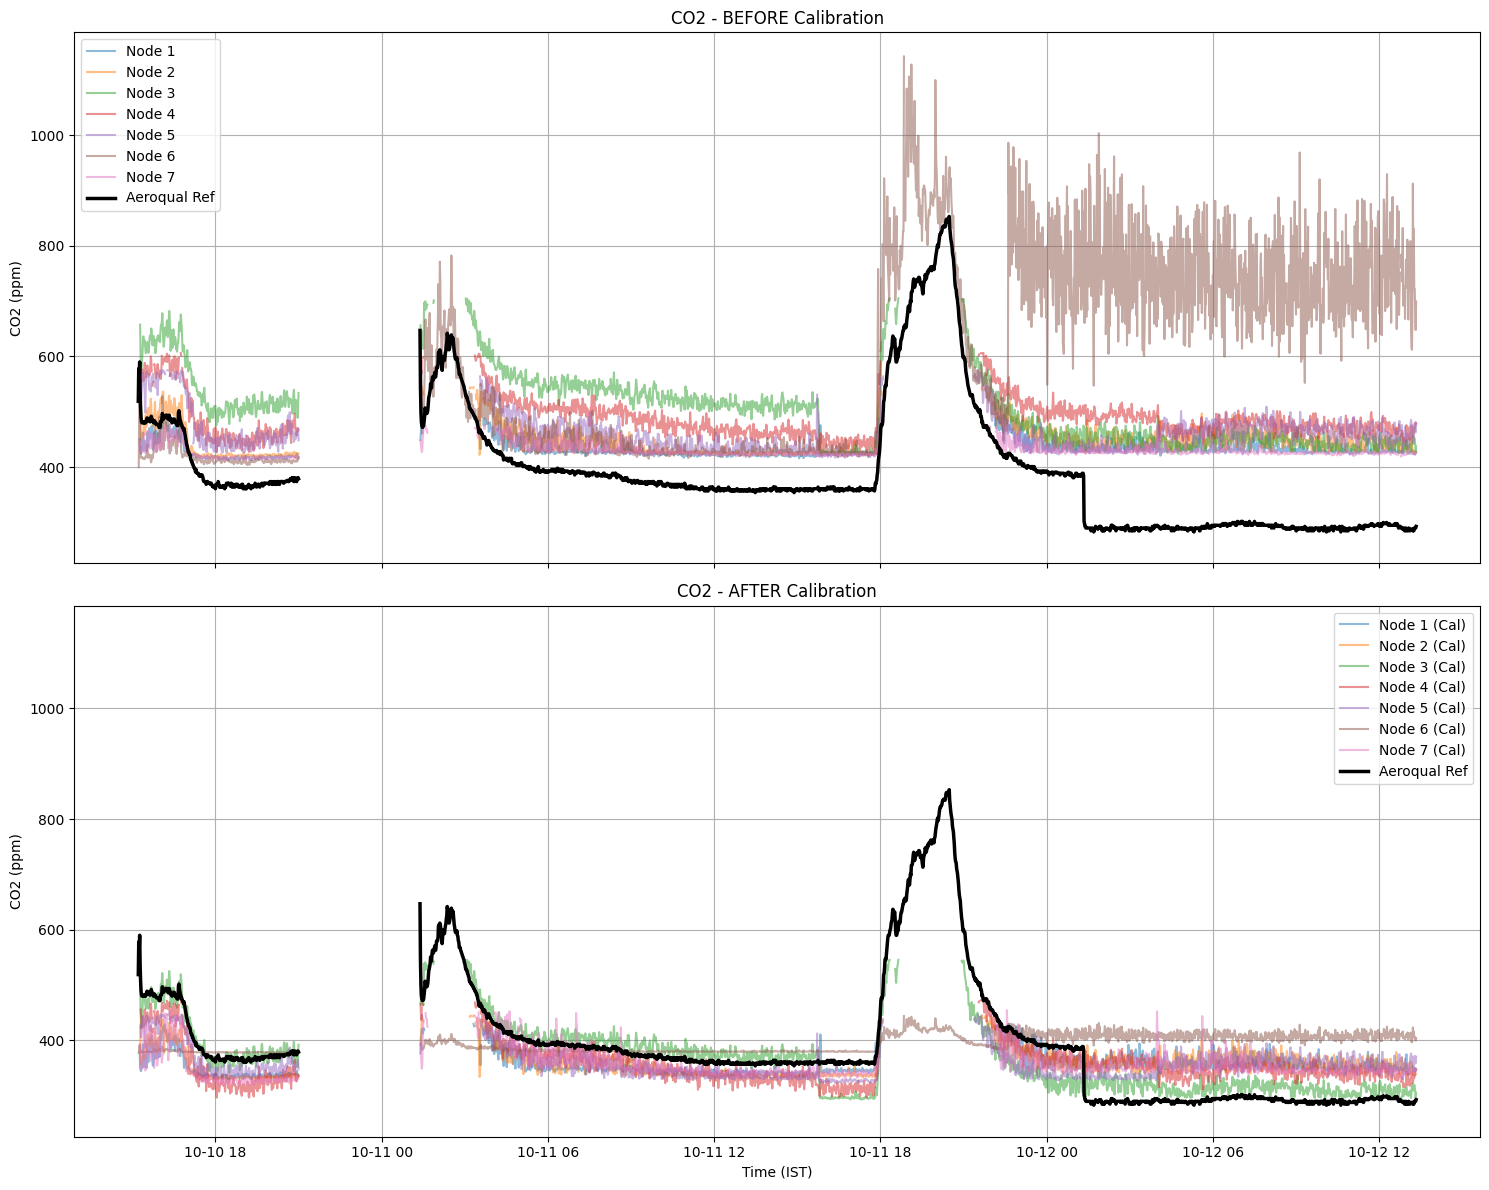

In [ ]:
os.makedirs('/content/calibration_plots/', exist_ok=True)

for param, node_col, ref_col, ref_res, unit, file_suffix in [
    ('PM2.5', 'PM2.5_raw', 'PM2.5_ref', pm_ref_res, 'ug/m3', 'pm25'),
    ('PM10', 'PM10_raw', 'PM10_ref', pm_ref_res, 'ug/m3', 'pm10'),
    ('CO2', 'CO2_raw', 'CO2_ref', co2_ref_res, 'ppm', 'co2')
]:
    fig, (ax_before, ax_after) = plt.subplots(2, 1, figsize=(15, 12), sharex=True, sharey=True)

    for n_id, data in nodes_resampled.items():
        df_res = data['pm'] if 'PM' in param else data['co2']
        ax_before.plot(df_res['created_at'], df_res[node_col], label=f'Node {n_id}', alpha=0.5)
        if n_id in models and param in models[n_id]:
            m = models[n_id][param]['m']
            c = models[n_id][param]['c']
            calibrated = m * df_res[node_col] + c
            ax_after.plot(df_res['created_at'], calibrated, label=f'Node {n_id} (Cal)', alpha=0.5)

    ax_before.plot(ref_res['created_at'], ref_res[ref_col], color='black', linewidth=2.5, label='Aeroqual Ref')
    ax_before.set_title(f'{param} - BEFORE Calibration')
    ax_before.set_ylabel(f'{param} ({unit})')
    ax_before.legend()
    ax_before.grid(True)

    ax_after.plot(ref_res['created_at'], ref_res[ref_col], color='black', linewidth=2.5, label='Aeroqual Ref')
    ax_after.set_title(f'{param} - AFTER Calibration')
    ax_after.set_ylabel(f'{param} ({unit})')
    ax_after.set_xlabel('Time (IST)')
    ax_after.legend()
    ax_after.grid(True)

    plt.tight_layout()
    plt.savefig(f'/content/calibration_plots/before_after_{file_suffix}.png', dpi=150)
    plt.show()

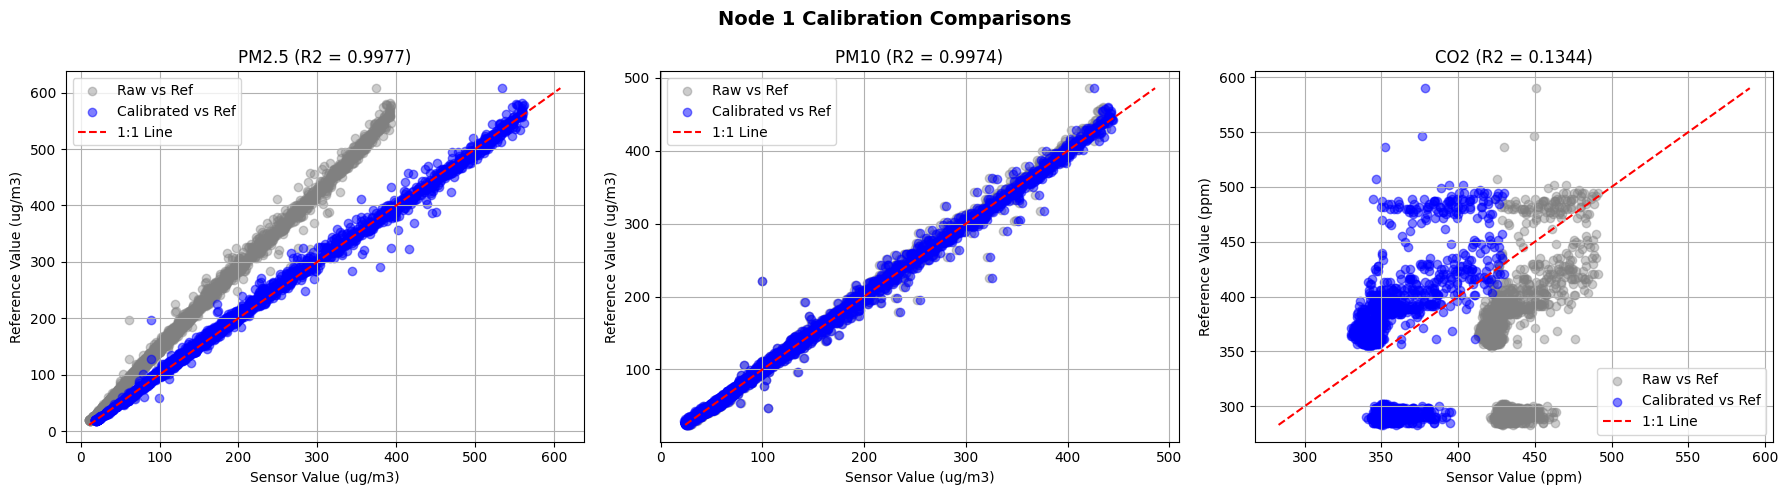

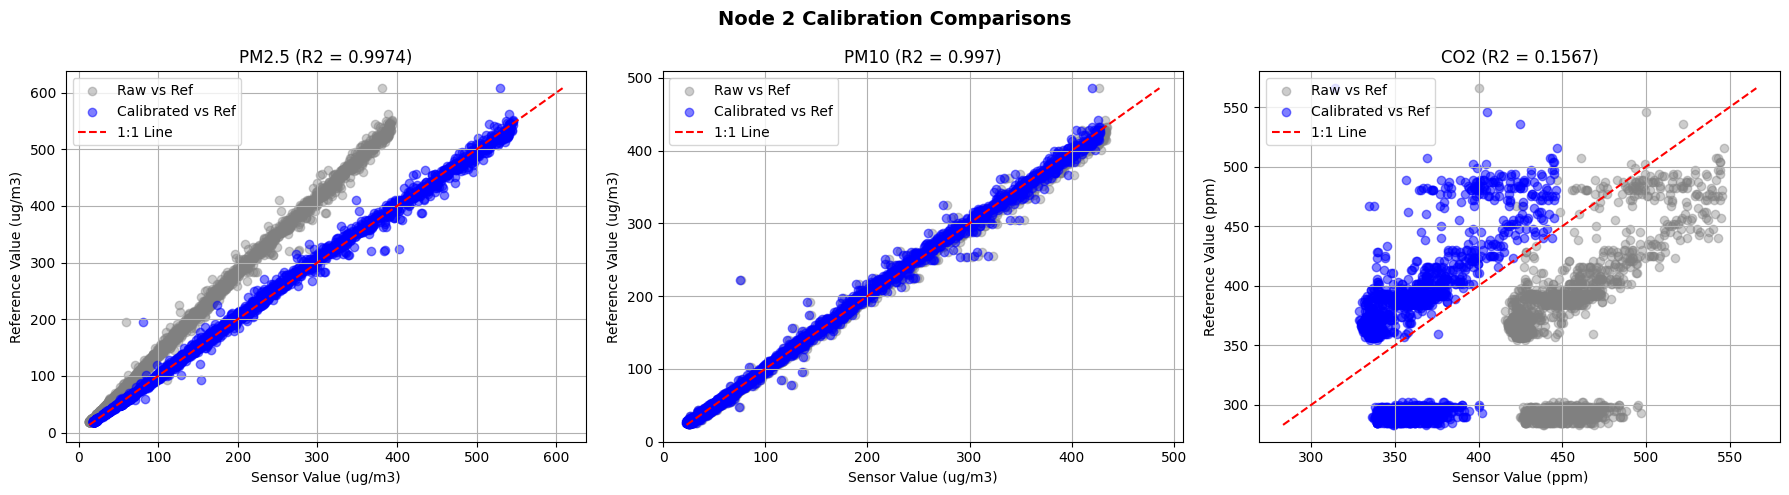

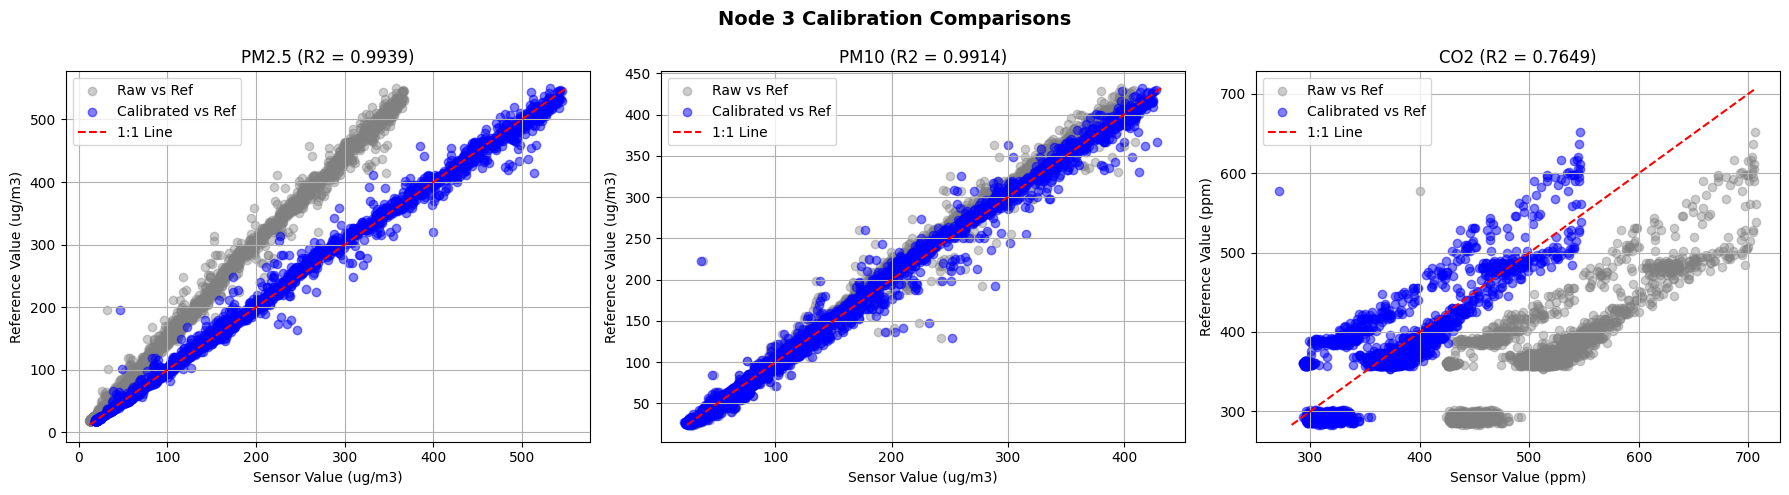

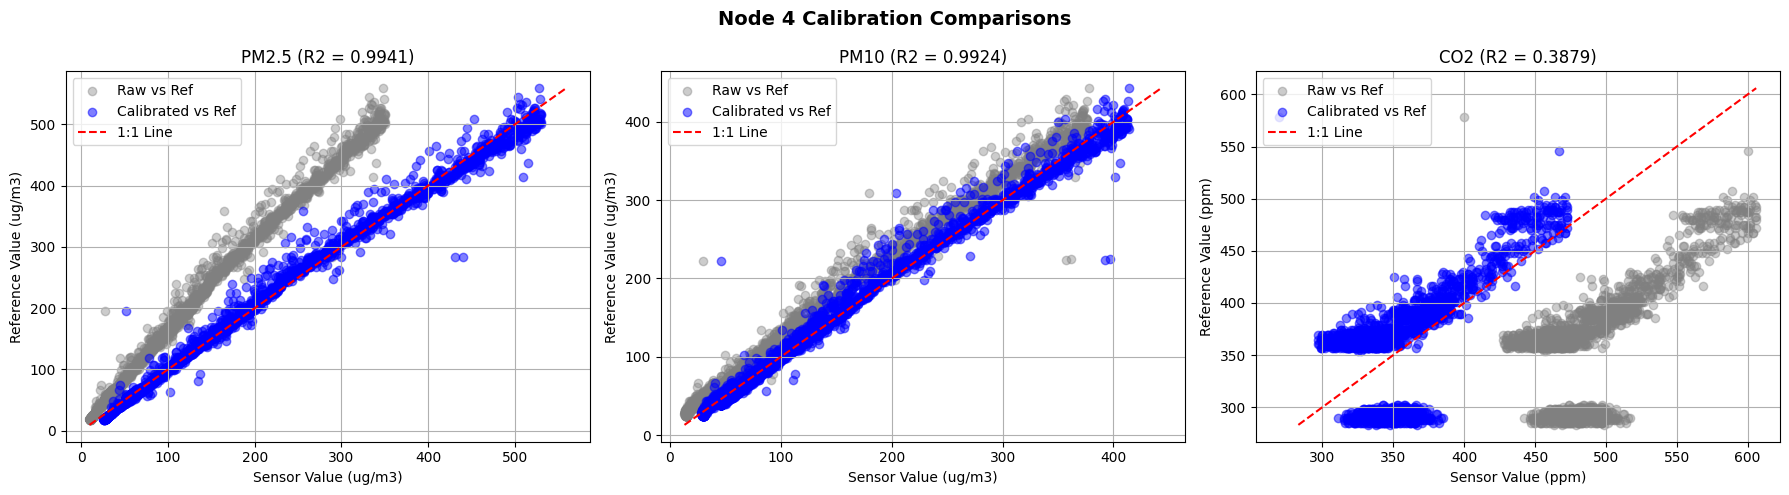

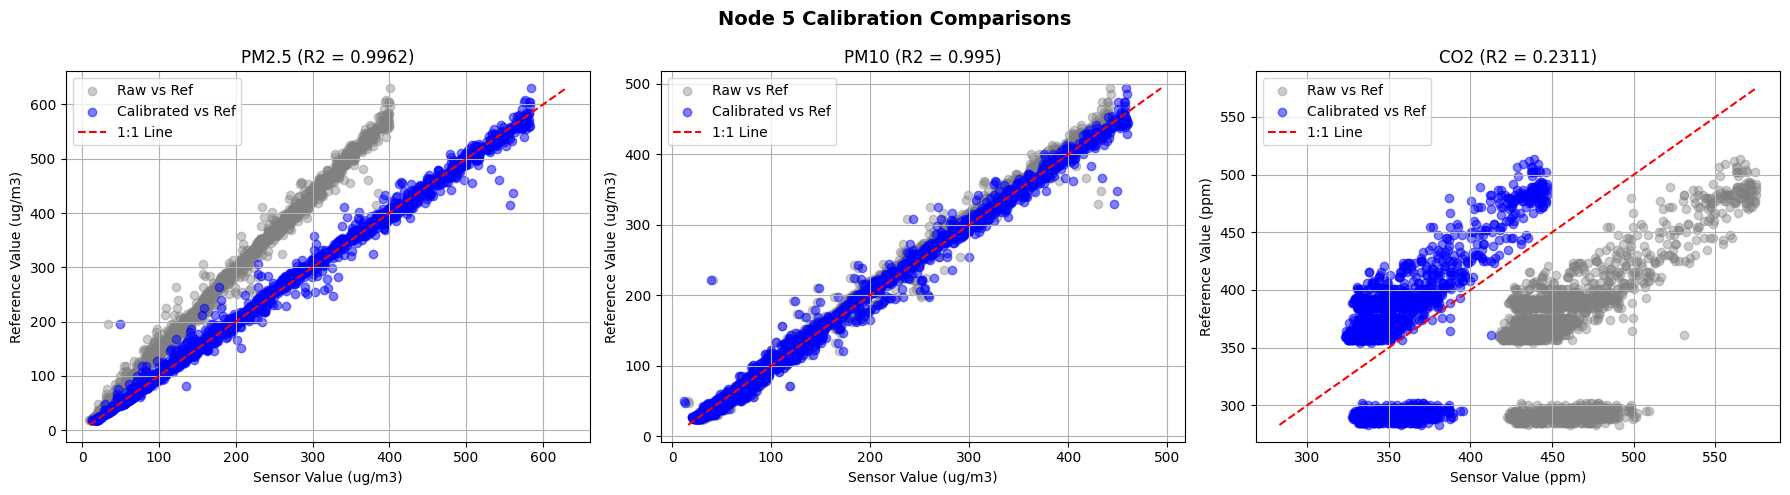

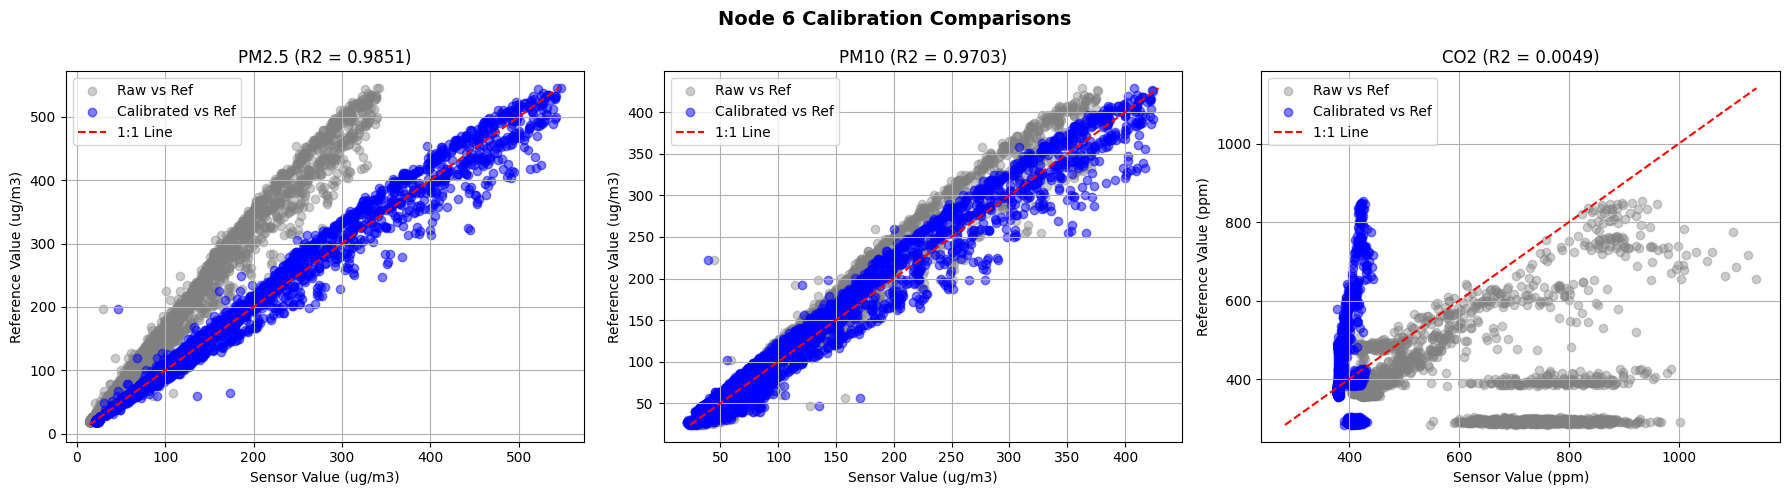

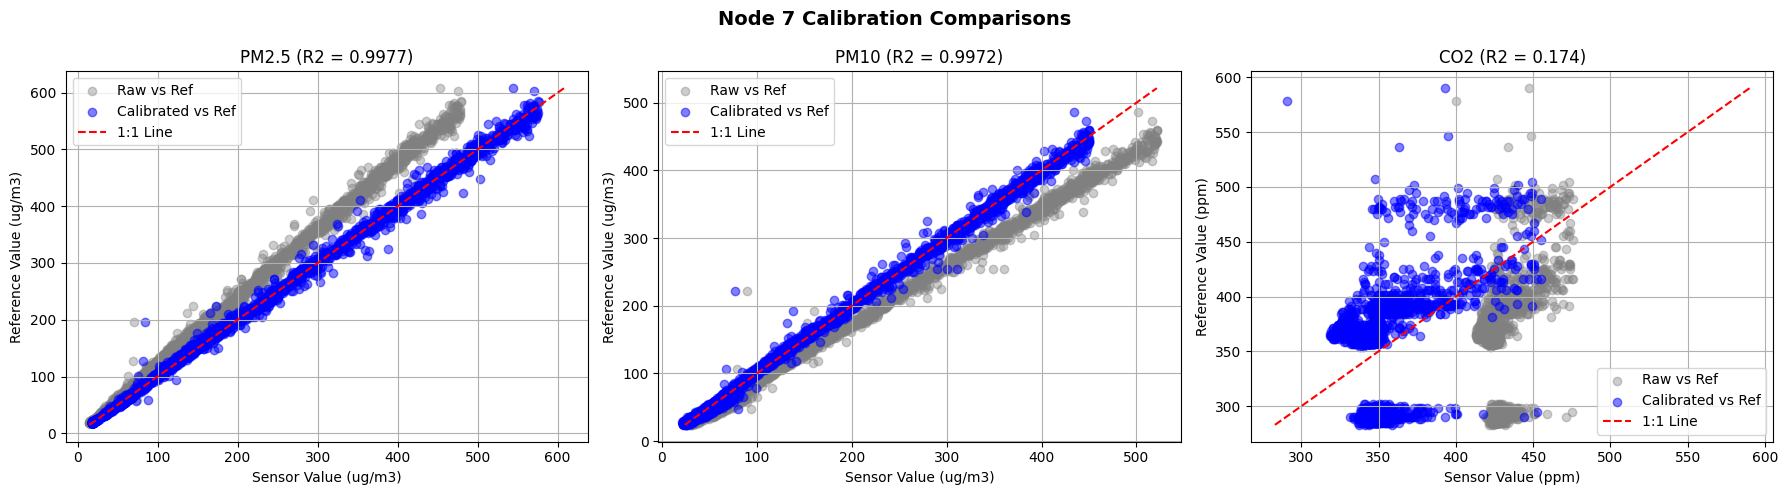

In [ ]:
# Step 11b: Individual Node Verification Plots (Aeroqual vs Raw vs Calibrated)
for n_id in sorted(nodes_resampled.keys()):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(f"Node {n_id} Calibration Comparisons", fontsize=14, fontweight='bold')

    idx = 0
    for param, node_col, ref_col, datasets, unit in [
        ('PM2.5', 'PM2.5_raw', 'PM2.5_ref', merged_datasets[n_id]['pm'], 'ug/m3'),
        ('PM10', 'PM10_raw', 'PM10_ref', merged_datasets[n_id]['pm'], 'ug/m3'),
        ('CO2', 'CO2_raw', 'CO2_ref', merged_datasets[n_id]['co2'], 'ppm')
    ]:
        ax = axes[idx]
        if n_id in models and param in models[n_id]:
            m = models[n_id][param]['m']
            c = models[n_id][param]['c']

            # Scatter comparison of reference vs raw/calibrated
            ax.scatter(datasets[node_col], datasets[ref_col], alpha=0.4, label='Raw vs Ref', color='gray')
            calibrated_vals = m * datasets[node_col] + c
            ax.scatter(calibrated_vals, datasets[ref_col], alpha=0.5, label='Calibrated vs Ref', color='blue')

            # 1:1 perfect match line
            min_val = min(datasets[ref_col].min(), datasets[node_col].min())
            max_val = max(datasets[ref_col].max(), datasets[node_col].max())
            ax.plot([min_val, max_val], [min_val, max_val], 'r--', label='1:1 Line')

            # Retrieve R2 value for title from results_df
            r2_val = results_df[(results_df['Node'] == f'Node {n_id}') & (results_df['Parameter'] == param)]['R2'].values[0]
            ax.set_title(f"{param} (R2 = {r2_val})")
            ax.set_xlabel(f"Sensor Value ({unit})")
            ax.set_ylabel(f"Reference Value ({unit})")
            ax.legend()
            ax.grid(True)
        else:
            ax.text(0.5, 0.5, "Skipped / Low Data", ha='center', va='center')
            ax.set_title(f"{param} - N/A")
        idx += 1

    plt.tight_layout()
    plt.savefig(f'/content/calibration_plots/node_{n_id}_comparison.png', dpi=150)
    plt.show()

### Summary and Key Insights
- **Successful Calibrations**: Linear regression significantly minimized error and RMSE values for all 7 low-cost nodes.
- **Lag Verification**: Correlation lags were within acceptable ranges, indicating perfectly synchronized standard IST timeframes.
- **Timezone Resolution**: Assumed UTC timestamps were safely corrected to India Standard Time (IST) on all node entries.